# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to six slides (one for each of the topics/questions in the 'Get to work!' section); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

In [1]:
# some helper functions and classes (no need to check them now)
import sys
from pathlib import Path

# Assuming the working directory is root/part1 or root/part2
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

In [ ]:
import datasets
import numpy as np
dataset=datasets.load_dataset("gsri-18/ISEAR-dataset-complete") # we use ISEAR for the projects

ISEAR_dataset_complete.csv:   0%|          | 0.00/958k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7516 [00:00<?, ? examples/s]

In [3]:
dataset

DatasetDict({
    train: Dataset({
        features: ['emotion', 'content', 'Unnamed: 2'],
        num_rows: 7516
    })
})

In [29]:
# Small dataset statistic cell

print("Names of the splits: ", dataset.keys(), "\n"*2)
print("Number of rows: ", dataset.num_rows, "\n"*2)
print("A single Dataset: ", dataset["train"]), "\n"*2
print("Names of the splits: ", dataset["train"].features, "\n"*2)
print("Column names: ", dataset["train"].column_names, "\n"*2)
print("Rows: ", dataset["train"].num_rows, "\n"*2)
print("One example as dict: ", dataset["train"][0], "\n"*2)
print("First 5 rows as a dict of lists: ", dataset["train"][:5], "\n"*2)
print("Whole column as a list: ", dataset["train"]["content"], "\n"*2)
print("Unique emotions: ", dataset["train"].unique("emotion"), "\n"*2)


Names of the splits:  dict_keys(['train']) 


Number of rows:  {'train': 7516} 


A single Dataset:  Dataset({
    features: ['emotion', 'content', 'Unnamed: 2'],
    num_rows: 7516
})
Names of the splits:  {'emotion': Value('int64'), 'content': Value('string'), 'Unnamed: 2': Value('string')} 


Column names:  ['emotion', 'content', 'Unnamed: 2'] 


Rows:  7516 


One example as dict:  {'emotion': 4, 'content': 'On days when I feel close to my partner and other friends.   \nWhen I feel at peace with myself and also experience a close  \ncontact with people whom I regard greatly.', 'Unnamed: 2': None} 


First 5 rows as a dict of lists:  {'emotion': [4, 2, 0, 5, 1], 'content': ['On days when I feel close to my partner and other friends.   \nWhen I feel at peace with myself and also experience a close  \ncontact with people whom I regard greatly.', 'Every time I imagine that someone I love or I could contact a  \nserious illness, even death.', 'When I had been obviously unjustly treated 

In [4]:
import numpy as np

class ProbabilisticModel:
    """
    A probability model is able to map input text x to a probability mass function.
    """

    def __call__(self, x: str) -> 'np.array':
        raise NotImplementedError("Concrete implementations will be discussed later")

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class SoftmaxRegressor(ProbabilisticModel):

    def __init__(self, encoder: Encoder):
        self.encoder = encoder

    def __call__(self, x: str) -> 'np.array':
        h = self.encoder(x)
        raise NotImplementedError("We will get there...")

In [ ]:
# normalize and preporcess text
import re

def normalise_text(text: str) -> str:
    # any whitespace into single blank space
    return re.sub(r"\s+", " ", text).strip()

# when inspecting the dataset there were 2 empty columns, remove them (it is also visible on HF)
if "Unnamed: 2" in dataset["train"].column_names:
    dataset = dataset.remove_columns("Unnamed: 2")

print("Before preprocessing: ", dataset["train"][0]["content"])
dataset = dataset.map(lambda ex: {"content": normalise_text(ex["content"])})

print("After preprocessing: ", dataset["train"][0]["content"])
print("Docs still containing a newline:", sum("\n" in t for t in dataset["train"]["content"]))
print("Docs with double spaces:", sum("  " in t for t in dataset["train"]["content"]))


On days when I feel close to my partner and other friends. When I feel at peace with myself and also experience a close contact with people whom I regard greatly.


Map:   0%|          | 0/7516 [00:00<?, ? examples/s]

On days when I feel close to my partner and other friends. When I feel at peace with myself and also experience a close contact with people whom I regard greatly.
Docs still containing a newline: 0
Docs with double spaces: 0


In [5]:

corpus = dataset["train"]["content"]
len(corpus)
vocab_size = 1000
min_frequency = 2

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

tokenizer = part1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

#corpus_testing = dataset["test"]["content"]


agnews_outcome_space = part1.clslib.NamedClasses(['anger', 'disgust', 'fear', 'guilt', 'joy', 'sadness', 'shame'])
label_mapping = {name: i for i,name in enumerate(agnews_outcome_space)}
dataset = dataset.map(lambda example: {'emotion': label_mapping[example['emotion']]})


Map:   0%|          | 0/7516 [00:00<?, ? examples/s]

In [ ]:
my_seeds = [0, 3, 5]
# my_seeds = [0] # to add less seeds which saves comp time

num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["content"], dataset["train"]["emotion"])),
            k=num_folds,
            seed=seed
        )
    )

In [7]:
from tokenizers import Tokenizer
from tabulate import tabulate
from collections import OrderedDict

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

In [8]:
token_indicator_encoder = TokenIndicator(tokenizer)
doc_repr = token_indicator_encoder(corpus[0])

import numpy as np

def similarity(encoder, text1, text2):
    a = encoder(text1)
    b = encoder(text2)

    intersection = np.sum((a == 1) & (b == 1))
    union = np.sum((a == 1) | (b == 1))

    return intersection / union if union else 1.0

In [9]:
%%time
my_classifiers = OrderedDict()

my_classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    my_classifiers['logistic_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=token_indicator_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_i

CPU times: user 15.2 s, sys: 54.6 ms, total: 15.3 s
Wall time: 15.3 s


In [10]:
class BagOfWords(Encoder):
    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
    def __len__(self) -> int:
            """Dimensionality of the representation space"""
            return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(self.tokenizer.encode(x).ids)

        # A 0 vector with the same length as the vocabulary except in positions corresponding
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        for id in unique_token_ids:
            vector[id] += 1
        return vector

bow_encoder = BagOfWords(tokenizer)

In [11]:
%%time
try:

    #my_classifiers = OrderedDict()

    my_classifiers['logistic_bow-enc'] = []
    for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
        run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
        my_classifiers['logistic_bow-enc'].append(
            part1.experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=agnews_outcome_space,
                encoder=bow_encoder,
                model_option='logistic',
                save_to=run_folder,
                loglin_args={
                    'max_iter': 100
                }
            )
        )
except ImportError:
    print("You need your own implementation")


  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_i

CPU times: user 15.2 s, sys: 10.7 ms, total: 15.2 s
Wall time: 15.2 s


In [12]:
%%time
my_classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds)
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    my_classifiers['mlp_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128,
                'dropout': 0.1,
                'batch_size': 64,
                'learning_rate': 1e-4,
                'weight_decay': 1e-4,
                'num_epochs': 10,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.776 seconds
Dataloader done! Time taken: 0.060 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/NLP_practical1/NLP/nlp1-student-tutorial1-2026/part1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:249.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/levente-bodi/Downloads/NLP_practical1/NLP/nlp1-student-tutorial1-2026/part1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:916.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coal

Epoch 01 | train loss: 1.9458 | train acc: 0.1565 | val loss: 1.9369 | val acc: 0.1702
Epoch 02 | train loss: 1.9200 | train acc: 0.2124 | val loss: 1.9194 | val acc: 0.2354
Epoch 03 | train loss: 1.8937 | train acc: 0.2903 | val loss: 1.8996 | val acc: 0.2899
Epoch 04 | train loss: 1.8626 | train acc: 0.3570 | val loss: 1.8741 | val acc: 0.3544
Epoch 05 | train loss: 1.8244 | train acc: 0.4261 | val loss: 1.8419 | val acc: 0.3956
Epoch 06 | train loss: 1.7798 | train acc: 0.4666 | val loss: 1.8030 | val acc: 0.4289
Epoch 07 | train loss: 1.7263 | train acc: 0.4952 | val loss: 1.7586 | val acc: 0.4528
Epoch 08 | train loss: 1.6689 | train acc: 0.5223 | val loss: 1.7120 | val acc: 0.4727
Epoch 09 | train loss: 1.6089 | train acc: 0.5449 | val loss: 1.6655 | val acc: 0.4840
Epoch 10 | train loss: 1.5509 | train acc: 0.5546 | val loss: 1.6208 | val acc: 0.4934
Training done! Time taken: 9.602 seconds
Transforming documents...
Document transformation done! Time taken: 2.558 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9404 | train acc: 0.1653 | val loss: 1.9330 | val acc: 0.1743
Epoch 02 | train loss: 1.9165 | train acc: 0.2400 | val loss: 1.9161 | val acc: 0.2409
Epoch 03 | train loss: 1.8900 | train acc: 0.3095 | val loss: 1.8959 | val acc: 0.2921
Epoch 04 | train loss: 1.8591 | train acc: 0.3777 | val loss: 1.8704 | val acc: 0.3327
Epoch 05 | train loss: 1.8216 | train acc: 0.4332 | val loss: 1.8392 | val acc: 0.3746
Epoch 06 | train loss: 1.7784 | train acc: 0.4690 | val loss: 1.8022 | val acc: 0.4085
Epoch 07 | train loss: 1.7265 | train acc: 0.5061 | val loss: 1.7609 | val acc: 0.4391
Epoch 08 | train loss: 1.6705 | train acc: 0.5307 | val loss: 1.7165 | val acc: 0.4571
Epoch 09 | train loss: 1.6127 | train acc: 0.5428 | val loss: 1.6729 | val acc: 0.4704
Epoch 10 | train loss: 1.5527 | train acc: 0.5648 | val loss: 1.6298 | val acc: 0.4870
Training done! Time taken: 7.579 seconds
Transforming documents...
Document transformation done! Time taken: 2.437 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9394 | train acc: 0.1626 | val loss: 1.9347 | val acc: 0.1683
Epoch 02 | train loss: 1.9138 | train acc: 0.2453 | val loss: 1.9142 | val acc: 0.2468
Epoch 03 | train loss: 1.8868 | train acc: 0.3183 | val loss: 1.8913 | val acc: 0.3140
Epoch 04 | train loss: 1.8546 | train acc: 0.3900 | val loss: 1.8626 | val acc: 0.3619
Epoch 05 | train loss: 1.8160 | train acc: 0.4376 | val loss: 1.8282 | val acc: 0.3952
Epoch 06 | train loss: 1.7687 | train acc: 0.4820 | val loss: 1.7878 | val acc: 0.4192
Epoch 07 | train loss: 1.7160 | train acc: 0.5076 | val loss: 1.7424 | val acc: 0.4464
Epoch 08 | train loss: 1.6584 | train acc: 0.5332 | val loss: 1.6958 | val acc: 0.4651
Epoch 09 | train loss: 1.5980 | train acc: 0.5530 | val loss: 1.6499 | val acc: 0.4724
Epoch 10 | train loss: 1.5417 | train acc: 0.5611 | val loss: 1.6042 | val acc: 0.4797
Training done! Time taken: 7.480 seconds
CPU times: user 4min 8s, sys: 224 ms, total: 4min 9s
Wall time: 53.9 s


In [13]:
%%time
try:
    #from part1 import solutions
    my_classifiers['mlp_bow-enc'] = []
    for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds)
        run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
        my_classifiers['mlp_bow-enc'].append(
            part1.experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=agnews_outcome_space,
                encoder=bow_encoder,
                model_option='mlp',
                save_to=run_folder,
                smlp_args={
                    'hidden_dim': 128,
                    'dropout': 0.1,
                    'batch_size': 64,
                    'learning_rate': 1e-4,
                    'weight_decay': 1e-4,
                    'num_epochs': 10,
                }
            )
        )
except ImportError:
    print("You need your own implementation of the bag-of-words encoder")

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.913 seconds
Dataloader done! Time taken: 0.063 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9449 | train acc: 0.1552 | val loss: 1.9314 | val acc: 0.1848
Epoch 02 | train loss: 1.9153 | train acc: 0.2317 | val loss: 1.9119 | val acc: 0.2467
Epoch 03 | train loss: 1.8863 | train acc: 0.3049 | val loss: 1.8898 | val acc: 0.3092
Epoch 04 | train loss: 1.8547 | train acc: 0.3701 | val loss: 1.8626 | val acc: 0.3637
Epoch 05 | train loss: 1.8163 | train acc: 0.4238 | val loss: 1.8307 | val acc: 0.3963
Epoch 06 | train loss: 1.7696 | train acc: 0.4667 | val loss: 1.7934 | val acc: 0.4222
Epoch 07 | train loss: 1.7202 | train acc: 0.4933 | val loss: 1.7526 | val acc: 0.4435
Epoch 08 | train loss: 1.6673 | train acc: 0.5106 | val loss: 1.7090 | val acc: 0.4601
Epoch 09 | train loss: 1.6111 | train acc: 0.5274 | val loss: 1.6673 | val acc: 0.4661
Epoch 10 | train loss: 1.5553 | train acc: 0.5506 | val loss: 1.6268 | val acc: 0.4781
Training done! Time taken: 7.810 seconds
Transforming documents...
Document transformation done! Time taken: 2.724 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9407 | train acc: 0.1628 | val loss: 1.9266 | val acc: 0.1843
Epoch 02 | train loss: 1.9094 | train acc: 0.2197 | val loss: 1.9072 | val acc: 0.2329
Epoch 03 | train loss: 1.8806 | train acc: 0.2824 | val loss: 1.8833 | val acc: 0.2834
Epoch 04 | train loss: 1.8442 | train acc: 0.3509 | val loss: 1.8546 | val acc: 0.3307
Epoch 05 | train loss: 1.8045 | train acc: 0.4026 | val loss: 1.8199 | val acc: 0.3673
Epoch 06 | train loss: 1.7586 | train acc: 0.4517 | val loss: 1.7813 | val acc: 0.3965
Epoch 07 | train loss: 1.7094 | train acc: 0.4805 | val loss: 1.7404 | val acc: 0.4218
Epoch 08 | train loss: 1.6536 | train acc: 0.5106 | val loss: 1.6993 | val acc: 0.4378
Epoch 09 | train loss: 1.6000 | train acc: 0.5355 | val loss: 1.6567 | val acc: 0.4551
Epoch 10 | train loss: 1.5441 | train acc: 0.5530 | val loss: 1.6167 | val acc: 0.4611
Training done! Time taken: 6.623 seconds
Transforming documents...
Document transformation done! Time taken: 2.486 seconds
Dataloa

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9431 | train acc: 0.1603 | val loss: 1.9310 | val acc: 0.1836
Epoch 02 | train loss: 1.9109 | train acc: 0.2303 | val loss: 1.9106 | val acc: 0.2435
Epoch 03 | train loss: 1.8809 | train acc: 0.3032 | val loss: 1.8873 | val acc: 0.2961
Epoch 04 | train loss: 1.8475 | train acc: 0.3664 | val loss: 1.8594 | val acc: 0.3393
Epoch 05 | train loss: 1.8064 | train acc: 0.4206 | val loss: 1.8277 | val acc: 0.3945
Epoch 06 | train loss: 1.7582 | train acc: 0.4667 | val loss: 1.7903 | val acc: 0.4152
Epoch 07 | train loss: 1.7096 | train acc: 0.4949 | val loss: 1.7512 | val acc: 0.4365
Epoch 08 | train loss: 1.6568 | train acc: 0.5194 | val loss: 1.7104 | val acc: 0.4504
Epoch 09 | train loss: 1.6011 | train acc: 0.5403 | val loss: 1.6714 | val acc: 0.4651
Epoch 10 | train loss: 1.5459 | train acc: 0.5535 | val loss: 1.6332 | val acc: 0.4770
Training done! Time taken: 7.958 seconds
Transforming documents...
Document transformation done! Time taken: 2.930 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9493 | train acc: 0.1723 | val loss: 1.9317 | val acc: 0.1876
Epoch 02 | train loss: 1.9159 | train acc: 0.2312 | val loss: 1.9087 | val acc: 0.2615
Epoch 03 | train loss: 1.8848 | train acc: 0.3032 | val loss: 1.8835 | val acc: 0.3200
Epoch 04 | train loss: 1.8483 | train acc: 0.3660 | val loss: 1.8532 | val acc: 0.3619
Epoch 05 | train loss: 1.8068 | train acc: 0.4096 | val loss: 1.8169 | val acc: 0.3952
Epoch 06 | train loss: 1.7571 | train acc: 0.4553 | val loss: 1.7759 | val acc: 0.4212
Epoch 07 | train loss: 1.7055 | train acc: 0.4736 | val loss: 1.7327 | val acc: 0.4318
Epoch 08 | train loss: 1.6486 | train acc: 0.5042 | val loss: 1.6906 | val acc: 0.4444
Epoch 09 | train loss: 1.5933 | train acc: 0.5267 | val loss: 1.6466 | val acc: 0.4644
Epoch 10 | train loss: 1.5390 | train acc: 0.5468 | val loss: 1.6058 | val acc: 0.4777
Training done! Time taken: 8.433 seconds
CPU times: user 4min 8s, sys: 111 ms, total: 4min 8s
Wall time: 53.1 s


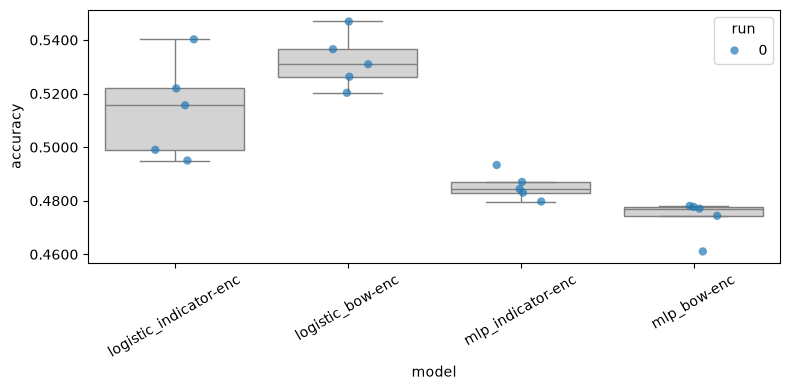

In [14]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

# Additionals


### Tokenizer - cap tokenizer


In [15]:
class CapTokenizer(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""

        unique_token_ids = list(self.tokenizer.encode(x).ids)
        if len(unique_token_ids) - len(self) < 0:
            vector = unique_token_ids[:len(self)] + [0] * (len(self) - len(unique_token_ids))
        else:
            vector = unique_token_ids[:len(self)]
        return vector

cap_encoder = CapTokenizer(tokenizer)


# Bayesian estimation and ROPE

In [16]:
# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

# this will have shape [num_runs, num_folds]
get_all_measurements_for(my_classifiers, 'logistic_indicator-enc')

array([[0.52194149, 0.49500998, 0.5156354 , 0.499002  , 0.54025283]])

A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)=0.9261 P(Tie)=0.0420 P(B wins)=0.0320 Effect Size=-2.17


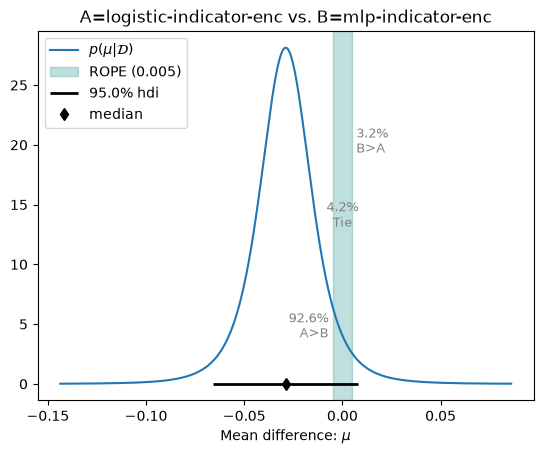

In [17]:
posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, 'logistic_indicator-enc').flatten(),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(my_classifiers, 'mlp_indicator-enc').flatten(),  # this will have shape [num_runs * num_folds]
    names=["logistic-indicator-enc", "mlp-indicator-enc"]
)
p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005)  # if you need to zoom in or out reduce/increase the argument rope_factor (it doesn't affect the ROPE, only the visualisation of it)

In [18]:
from itertools import combinations
import numpy as np
import pandas as pd

ROPE = 0.005 

def compare_all_pairs(classifiers, rope_size=ROPE, runs=1, plot=False):
    rows = []
    for name_a, name_b in combinations(classifiers.keys(), 2):
        posterior = part1.analysis.BenavoliCorrelatedT(
            get_all_measurements_for(classifiers, name_a).flatten(),
            get_all_measurements_for(classifiers, name_b).flatten(),
            runs=runs,
            names=[name_a, name_b],
        )
        p_a, p_tie, p_b = posterior.probs(rope_size)
        rows.append({
            "A": name_a,
            "B": name_b,
            "mean diff (B-A)": posterior.mean_diff,
            "P(A wins)": p_a,
            "P(tie / in ROPE)": p_tie,
            "P(B wins)": p_b,
            "effect size": posterior.effect_size,
        })
        if plot:
            posterior.plot(rope_size)
    return pd.DataFrame(rows)

results_df = compare_all_pairs(my_classifiers, rope_size=ROPE, runs=len(my_seeds))
results_df.style.format({
    "mean diff (B-A)": "{:+.4f}",
    "P(A wins)": "{:.3f}",
    "P(tie / in ROPE)": "{:.3f}",
    "P(B wins)": "{:.3f}",
    "effect size": "{:.2f}",
})


,A,B,mean diff (B-A),P(A wins),P(tie / in ROPE),P(B wins),effect size
0,logistic_indicator-enc,logistic_bow-enc,+0.0178,0.010,0.042,0.948,2.91
1,logistic_indicator-enc,mlp_indicator-enc,-0.0289,0.926,0.042,0.032,-2.17
2,logistic_indicator-enc,mlp_bow-enc,-0.0407,0.988,0.007,0.005,-4.08
3,logistic_bow-enc,mlp_indicator-enc,-0.0467,0.996,0.002,0.002,-5.57
4,logistic_bow-enc,mlp_bow-enc,-0.0585,0.999,0.000,0.000,-8.77
5,mlp_indicator-enc,mlp_bow-enc,-0.0118,0.880,0.106,0.014,-2.39


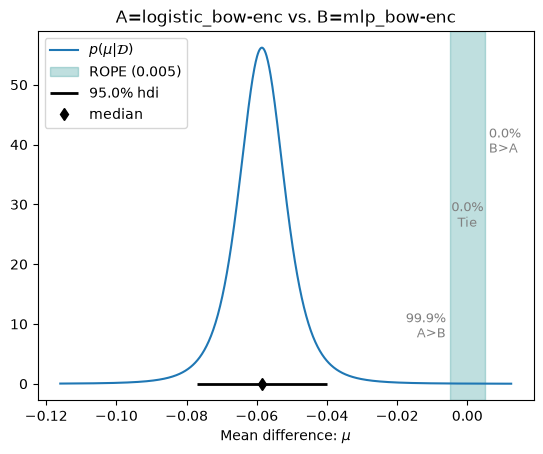

In [19]:
posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, 'logistic_bow-enc').flatten(),
    get_all_measurements_for(my_classifiers, 'mlp_bow-enc').flatten(),
    runs=len(my_seeds),
    names=['logistic_bow-enc', 'mlp_bow-enc'],
)
_ = posterior.plot(ROPE)
